# Do historical credit features add value?

Adding selected credit-history aggregates raises mean OOF AUC from **0.746335 to 0.755201**. The paired gain is **+0.008635 to +0.009098** across two predeclared model seeds, larger than the observed seed spread. Both feature sets use identical applicants, five fixed stratified folds and 100 boosting rounds without early stopping. This supports retaining history information within this controlled recipe; it is separate from the full benchmark.

This executed analysis reads only committed aggregate results. Training data, row-level OOF predictions and model weights remain private.

## Hypothesis and controlled comparison

Credit history may add behavioral information beyond the current application. Only inclusion of the already-selected relational aggregates changes within each seed. Rows, five fold assignments, LightGBM parameters and a fixed 100-round final budget stay matched. This bounded comparison is separate from the full early-stopped benchmark.

[Detailed method and rerun command](../docs/modeling-study.md).

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "docs").is_dir():
    ROOT = ROOT.parent
study = json.loads((ROOT / "docs/modeling-study.json").read_text())
assert study["status"] == "completed"
assert hashlib.sha256((ROOT / "scripts/ablation_study.py").read_bytes()).hexdigest() == study["script_sha256"]
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print("Source: docs/modeling-study.json; input and assignment hashes retained in receipt")
print("Observed total runtime (s):", round(study["elapsed_seconds"], 1))


Source: docs/modeling-study.json; input and assignment hashes retained in receipt
Observed total runtime (s): 264.0


## Retain every matched result

Model seeds 0 and 1 change stochastic row/feature sampling on the same split-seed-1001 partitions. Each point is one full pooled OOF score. Two realizations describe training-seed sensitivity; they do not establish a sampling distribution or universal stability.

In [2]:
labels = {"application_only": "Application", "application_plus_relational": "Application + history"}
rows = pd.DataFrame([{"Model seed": run["model_seed"], "Features": labels[run["variant"]], "Feature count": run["features"], "OOF AUC": run["pooled_oof_roc_auc"], "Fold SD (descriptive)": run["fold_sample_sd"]} for run in study["runs"]])
display(rows.round(6))


,Model seed,Features,Feature count,OOF AUC,Fold SD (descriptive)
0,0,Application,129,0.746278,0.004938
1,0,Application + history,528,0.755376,0.004081
2,1,Application,129,0.746391,0.004810
3,1,Application + history,528,0.755025,0.003860


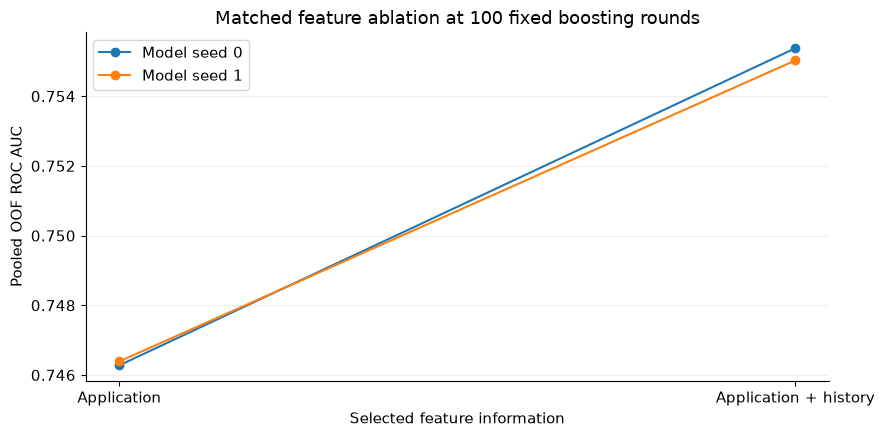

In [3]:
fig, ax = plt.subplots()
for seed, group in rows.groupby("Model seed", sort=True):
    ordered = group.set_index("Features").loc[list(labels.values())]
    ax.plot(range(2), ordered["OOF AUC"], marker="o", label=f"Model seed {seed}")
ax.set(xticks=range(2), xticklabels=list(labels.values()), ylabel="Pooled OOF ROC AUC", xlabel="Selected feature information", title="Matched feature ablation at 100 fixed boosting rounds")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


## Compare changes within each seed

Subtract the simpler variant from the richer variant within the same split and training budget. Pairing prevents a changed partition from explaining the component effect.

,add_relational_auc_delta
model_seed,
0,0.009098
1,0.008635


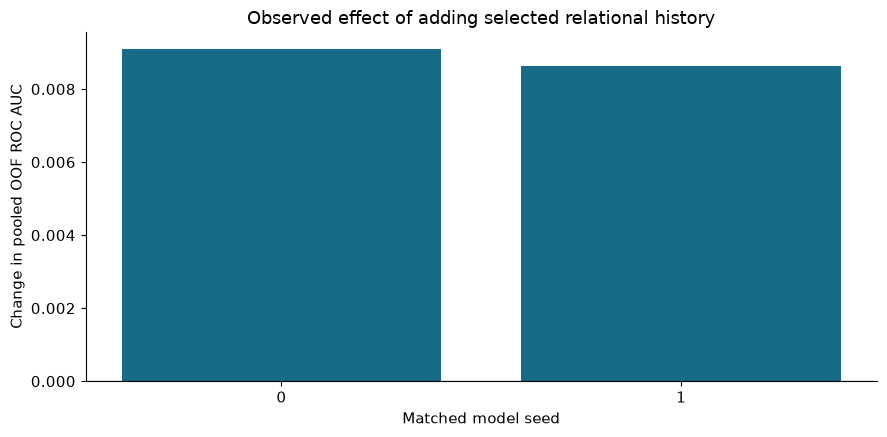

In [4]:
paired = pd.DataFrame(study["paired_deltas"]).set_index("model_seed")
display(paired.round(6))
fig, ax = plt.subplots()
ax.bar([str(seed) for seed in paired.index], paired["add_relational_auc_delta"], color="#176b87")
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="Matched model seed", ylabel="Change in pooled OOF ROC AUC", title="Observed effect of adding selected relational history")
fig.tight_layout()
plt.show()


## Interpretation and limits

Two model seeds are descriptive evidence, not a confidence interval. The effect is conditional on this selected feature recipe and 100-round budget. The inherited cache includes unlabeled transductive summaries; this is not prospective, train-only lending validation. The full benchmark remains a separate experiment.

The aggregate receipt retains per-fold metrics, exact configurations, source/input/assignment/output hashes and independent reload checks. [Study receipt](../docs/modeling-study.json) · [Main walkthrough](./01-credit-risk.ipynb)